# 01. E-mini S&P 500 Options Data from Databento

Everything in this case study starts from one table: the price of every
listed option on the S&P 500 at the close of one session. This guide is
about where that table comes from and what is in it.

In HW 2 you pulled 30-Day Fed Funds futures from Databento's CME Globex
feed with four parameters: a dataset, a schema, a symbol, and the kind of
symbol it was. Options on futures use the same feed, and the pull in
`src/pull_es_options.py` is written for you this time. What is new is the
data: options have a strike and an expiration, so one product is
thousands of contracts, and the price we want is not a trade but a
**settlement**.

**In this guide**

- Which options: the end-of-month E-mini S&P 500 options, and why them.
- Which price: the exchange's settlement, from the `statistics` schema,
  and why not daily bars.
- Which contract is which: the `definition` schema.
- One session's chain and its smile.
- Where the strikes stop, which is the point of the whole exercise.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import monitor
import pull_es_options
import pull_fred
import smile
from settings import config

DATA_DIR = Path(config("DATA_DIR"))
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

options = pull_es_options.load_es_options()
futures = pull_es_options.load_es_futures()
fred = pull_fred.load_fred()
# The newest session the monitor computed a row for (a session it had to
# skip, a rare chain with too few usable strikes, is not shown here either).
computed = set(monitor.load_history()["date"]) & set(options["date"])
latest = max(computed) if computed else options["date"].max()
print(f"{len(options):,} option settlements over {options['date'].nunique()} sessions, "
      f"{options['date'].min().date()} to {latest.date()}")

15,412 option settlements over 5 sessions, 2026-10-19 to 2026-10-23


## Which options: the E-mini end-of-month family

The E-mini S&P 500 future (CME root `ES`) is the most traded equity index
contract in the world, and CME lists several families of options on it.
The quarterly options expire with the future itself, in the morning, and
are American-style. The **end-of-month options** (root `EW`) and the
weekly options (`EW1` to `EW4` for Fridays, others for Monday to Thursday)
are European-style and settle at 4:00 p.m. ET, in the afternoon, like the
SPX options the academic literature uses. The end-of-month family alone
gives an expiration every month about seven months out, and then
quarterly, which is enough to bracket a 30-day horizon on every session.
That is what we pull.

Each option exercises into a future, the nearest quarterly `ES` contract
that expires after the option does. Databento's `definition` records say
which:

In [2]:
latest_chain = options[options["date"] == latest]
expiries = (
    latest_chain.groupby("expiration")
    .agg(days_to_expiry=("days_to_expiry", "first"), contracts=("symbol", "size"),
         strikes=("strike", "nunique"), underlying=("underlying", "first"),
         lowest_strike=("strike", "min"), highest_strike=("strike", "max"))
)
expiries

,days_to_expiry,contracts,strikes,underlying,lowest_strike,highest_strike
expiration,,,,,,
2026-10-30,7,808,404,ESZ6,100.0,10800.0
2026-11-30,38,330,165,ESZ6,100.0,10800.0
2026-12-31,69,358,179,ESH7,100.0,11200.0
2027-01-29,98,228,114,ESH7,1600.0,11200.0
2027-02-26,126,222,111,ESH7,1600.0,11200.0
2027-03-31,159,250,125,ESM7,1400.0,11200.0
2027-06-30,250,252,126,ESU7,1400.0,11400.0
2027-09-30,342,254,127,ESZ7,1400.0,11400.0
2027-12-31,434,236,118,ESH8,1600.0,11600.0


## Which price: the settlement

A daily bar (`ohlcv-1d`, the schema HW 2 used) exists for a contract only
on a day it traded, and most listed strikes do not trade on most days.
What exists for every listed contract every day is the exchange's
**settlement price**: the value CME assigns at the close to mark
positions, from the quotes near the money and a model in the wings. It is
published in the `statistics` schema, as one record type among several
(`stat_type` 3; the schema also carries the open interest, the session
high and low, and others), twice a day, a preliminary and a final; the
pull keeps the final.

The four parameters of the pull, then, are the dataset and symbology you
know from HW 2, a different parent symbol, and a different schema:

In [3]:
pull_es_options.build_queries("2026-10-15", "2026-10-16")["option_statistics"]

{'dataset': 'GLBX.MDP3',
 'symbols': ['EW.OPT'],
 'stype_in': 'parent',
 'start': '2026-10-15',
 'end': '2026-10-16',
 'schema': 'statistics'}

## Which contract is which: the `definition` schema

A `statistics` record names its contract by `instrument_id` and by symbol,
and the symbol, `EWV6 P7850` say, reads: root `EW`, month code `V`
(October), year digit `6`, a put, strike 7850. It does not carry the
expiration date. The exchange's `definition` records do, along with the
strike, the right, and the underlying future, and they are republished
every day for every listed contract, so the pull takes the same day's
definitions and joins them on `instrument_id`. Parent-symbol queries also
return user-defined spreads, multi-leg strategies that market
participants register intraday; their `instrument_class` is not C or P and
they are dropped.

The result, one row per settled contract per session:

In [4]:
latest_chain.sort_values(["expiration", "strike", "cp_flag"]).head(8)

,date,symbol,instrument_id,expiration,days_to_expiry,strike,cp_flag,settle,underlying
12244,2026-10-23,EWV6 C100,42716737,2026-10-30,7,100.0,C,7553.75,ESZ6
12245,2026-10-23,EWV6 P100,42477367,2026-10-30,7,100.0,P,0.05,ESZ6
12246,2026-10-23,EWV6 C1600,43001763,2026-10-30,7,1600.0,C,6055.00,ESZ6
12247,2026-10-23,EWV6 P1600,42931720,2026-10-30,7,1600.0,P,0.05,ESZ6
12248,2026-10-23,EWV6 C1800,43003134,2026-10-30,7,1800.0,C,5855.25,ESZ6
12249,2026-10-23,EWV6 P1800,43001769,2026-10-30,7,1800.0,P,0.05,ESZ6
12250,2026-10-23,EWV6 C2000,42913647,2026-10-30,7,2000.0,C,5655.25,ESZ6
12251,2026-10-23,EWV6 P2000,43003733,2026-10-30,7,2000.0,P,0.05,ESZ6


## One session's chain

Take the expiration that brackets 30 days from the near side, and look at
the settlements across strikes. Calls fall in the strike and puts rise,
and at the strike where the two cross, put-call parity gives the price of
the underlying future: $F = K + e^{r\tau}(C - P)$. The pull keeps the
future's own settlement too, so the parity-implied forward can be checked
against it.

Session 2026-10-23, expiration 2026-10-30 (7 days), risk-free rate 4.11%
Parity-implied forward: 7,659.75; the ESZ6 future settled at 7,659.75


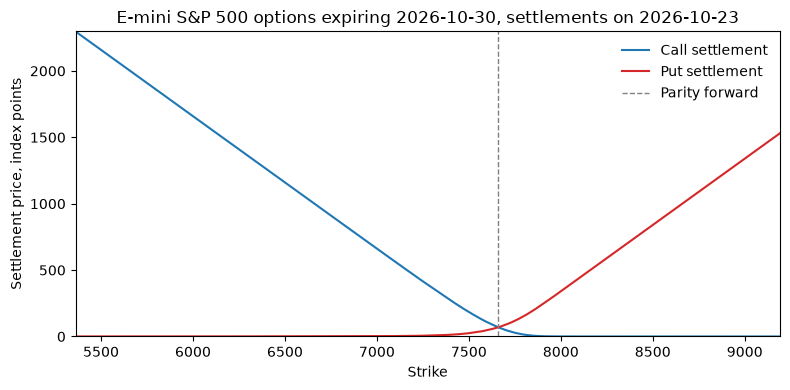

In [5]:
near, far = smile.bracketing_expiries(latest_chain)
rate = pull_fred.rate_on(fred, latest)
chain = latest_chain[latest_chain["expiration"] == near]
tau = int(chain["days_to_expiry"].iloc[0]) / 365
forward = smile.parity_forward(chain, rate, tau)
es_settle = futures[(futures["date"] == latest) & (futures["symbol"] == chain["underlying"].iloc[0])]["settle"].iloc[0]
print(f"Session {latest.date()}, expiration {pd.Timestamp(near).date()} ({chain['days_to_expiry'].iloc[0]} days), "
      f"risk-free rate {100 * rate:.2f}%")
print(f"Parity-implied forward: {forward:,.2f}; the {chain['underlying'].iloc[0]} future settled at {es_settle:,.2f}")

wide = chain.pivot_table(index="strike", columns="cp_flag", values="settle")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(wide.index, wide["C"], label="Call settlement", color="#1f77b4")
ax.plot(wide.index, wide["P"], label="Put settlement", color="#d62728")
ax.axvline(forward, color="gray", ls="--", lw=1, label="Parity forward")
ax.set_xlim(0.7 * forward, 1.2 * forward)
ax.set_ylim(0, 0.3 * forward)
ax.set_xlabel("Strike")
ax.set_ylabel("Settlement price, index points")
ax.set_title(f"E-mini S&P 500 options expiring {pd.Timestamp(near).date()}, settlements on {latest.date()}")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## The smile

A price is hard to compare across strikes; an implied volatility is not.
`smile.surface_from_chain` inverts each out-of-the-money settlement, puts
below the forward and calls above it, to the volatility that makes the
Black-76 formula return it, with the discounted forward $F e^{-r\tau}$
standing in for the spot (the `black_scholes` module explains why that
identity is exact for options on a future). The strike becomes moneyness,
$k = K / S^*$, so that a strike and a gross-return level are the same
number.

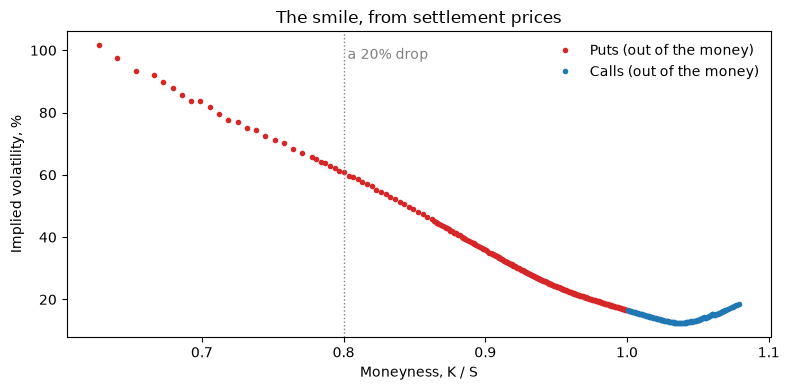

347 usable strikes, moneyness from 0.63 to 1.08


In [6]:
surface = smile.surface_from_chain(chain, rate)
fig, ax = plt.subplots(figsize=(8, 4))
for flag, color, label in [("P", "#d62728", "Puts (out of the money)"), ("C", "#1f77b4", "Calls (out of the money)")]:
    s = surface[surface["cp_flag"] == flag]
    ax.plot(s["moneyness"], 100 * s["implied_vol"], ".", color=color, label=label)
ax.axvline(0.80, color="gray", ls=":", lw=1)
ax.text(0.80, ax.get_ylim()[1] * 0.95, " a 20% drop", va="top", color="gray")
ax.set_xlabel("Moneyness, K / S")
ax.set_ylabel("Implied volatility, %")
ax.set_title("The smile, from settlement prices")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"{len(surface)} usable strikes, moneyness from {surface['moneyness'].min():.2f} to {surface['moneyness'].max():.2f}")

Two things to notice. The smile is a smirk: out-of-the-money puts are
dearer, in volatility terms, than out-of-the-money calls, because a market
fall is what people insure against. And the strikes go deep: the lowest
usable put is far below the 20% drop that the next guide prices.

Not every settlement is usable. CME's smallest premium tick is 0.05 index
points, and a deep out-of-the-money option whose settlement sits at that
tick is marked at a floor, not priced; the inversion treats it as if it
were a price and returns an absurd volatility. The pull keeps those rows
(they are what the exchange published), and `surface_from_chain` drops
them before inverting:

In [7]:
at_floor = chain[chain["settle"] <= smile.MIN_SETTLE]
print(f"{len(at_floor)} of {len(chain)} contracts settled at or below the minimum tick of {smile.MIN_SETTLE}; "
      f"strikes {at_floor['strike'].min():,.0f} to {at_floor['strike'].max():,.0f}")

57 of 808 contracts settled at or below the minimum tick of 0.05; strikes 100 to 10,800


## Where the strikes stop

This is the reason the case study uses the exchange's prices rather than a
vendor's fitted surface. OptionMetrics' standardized surface, the data of
guide 04, stops at the 10-delta put, which at 30 days sits around 92% of
the spot; a 20% drop lies beyond it, in a region the vendor fills by
extrapolation. The exchange lists, and settles, strikes far past it:

In [8]:
rows = []
for d, session in options.groupby("date"):
    try:
        near_d, _ = smile.bracketing_expiries(session)
        s = smile.surface_from_chain(session[session["expiration"] == near_d], pull_fred.rate_on(fred, d))
        puts = s[s["cp_flag"] == "P"]
        rows.append({"date": d.date(), "days": int(s["days_to_maturity"].iloc[0]),
                     "deepest usable put (K/S)": puts["moneyness"].min(),
                     "puts below K/S = 0.80": int((puts["moneyness"] <= 0.80).sum())})
    except ValueError:
        continue
pd.DataFrame(rows).set_index("date")

,days,deepest usable put (K/S),puts below K/S = 0.80
date,,,
2026-10-19,11,0.517804,36
2026-10-20,10,0.567995,34
2026-10-21,9,0.660901,28
2026-10-22,8,0.623574,29
2026-10-23,7,0.627146,27


Every session has a dozen or more quoted puts below the crash threshold.
The density the next guide builds in that region comes from prices, not
from a convention.